<a href="https://colab.research.google.com/github/moyan-li/MSSP607/blob/main/Assignments/assignment1/assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from google.colab import userdata
import os

github_token = userdata.get('Key1')
owner = 'moyan-li' # Replace with the GitHub repository owner
repository = 'MSSP607' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
!git clone {clone_url}

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import trim_mean, median_abs_deviation, skew

Mounted at /content/drive
Cloning into 'MSSP607'...
remote: Enumerating objects: 269, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 269 (delta 26), reused 20 (delta 15), pack-reused 221 (from 1)
Receiving objects: 100% (269/269), 11.97 MiB | 10.68 MiB/s, done.
Resolving deltas: 100% (135/135), done.


In [ ]:
df = pd.read_excel("/content/drive/MyDrive/MSSP607/Assignments/Assignment1/data_academic_performance.xlsx")


print(df.columns.tolist())

# Data types, missing values and basic statistics
df.info()
display(df.isna().sum().sort_values(ascending=False).head(20))
display(df.describe(include="all").T)
# Data quality inspection and cleaning

# Check the variable with the most missing values
missing_summary = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .to_frame(name="missing_count")
)

missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(df) * 100
)

display(missing_summary.head(20))

['COD_S11', 'GENDER', 'EDU_FATHER', 'EDU_MOTHER', 'OCC_FATHER', 'OCC_MOTHER', 'STRATUM', 'SISBEN', 'PEOPLE_HOUSE', 'Unnamed: 9', 'INTERNET', 'TV', 'COMPUTER', 'WASHING_MCH', 'MIC_OVEN', 'CAR', 'DVD', 'FRESH', 'PHONE', 'MOBILE', 'REVENUE', 'JOB', 'SCHOOL_NAME', 'SCHOOL_NAT', 'SCHOOL_TYPE', 'MAT_S11', 'CR_S11', 'CC_S11', 'BIO_S11', 'ENG_S11', 'Cod_SPro', 'UNIVERSITY', 'ACADEMIC_PROGRAM', 'QR_PRO', 'CR_PRO', 'CC_PRO', 'ENG_PRO', 'WC_PRO', 'FEP_PRO', 'G_SC', 'PERCENTILE', '2ND_DECILE', 'QUARTILE', 'SEL', 'SEL_IHE']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12411 entries, 0 to 12410
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COD_S11           12411 non-null  object 
 1   GENDER            12411 non-null  object 
 2   EDU_FATHER        12411 non-null  object 
 3   EDU_MOTHER        12411 non-null  object 
 4   OCC_FATHER        12411 non-null  object 
 5   OCC_MOTHER        12411 non-null  object

,0
Unnamed: 9,12411
GENDER,0
EDU_FATHER,0
EDU_MOTHER,0
COD_S11,0
OCC_FATHER,0
OCC_MOTHER,0
SISBEN,0
STRATUM,0
PEOPLE_HOUSE,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
COD_S11,12411,12411,SB11201420583232,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GENDER,12411,2,M,7368,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EDU_FATHER,12411,12,Complete professional education,3016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EDU_MOTHER,12411,12,Complete Secundary,3106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OCC_FATHER,12411,12,Independent,2907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OCC_MOTHER,12411,12,Home,4658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STRATUM,12411,7,Stratum 3,4045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SISBEN,12411,6,It is not classified by the SISBEN,7534,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PEOPLE_HOUSE,12411,13,Four,4767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unnamed: 9,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent
Unnamed: 9,12411,100.0
GENDER,0,0.0
EDU_FATHER,0,0.0
EDU_MOTHER,0,0.0
COD_S11,0,0.0
OCC_FATHER,0,0.0
OCC_MOTHER,0,0.0
SISBEN,0,0.0
STRATUM,0,0.0
PEOPLE_HOUSE,0,0.0


In [ ]:
#2.1 Numerical descriptive statistics
score_cols = [
    "MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11",
    "QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO",
    "FEP_PRO", "G_SC"
]

numeric_summary = (
    df[score_cols]
      .describe(percentiles=[0.25, 0.50, 0.75])
      .T
      .rename(columns={
          "count": "n",
          "mean": "mean",
          "std": "std",
          "min": "min",
          "25%": "Q1",
          "50%": "median",
          "75%": "Q3",
          "max": "max"
      })
)

display(numeric_summary.round(2))
display(numeric_summary.loc[["G_SC"]].round(2))



,n,mean,std,min,Q1,median,Q3,max
MAT_S11,12411.0,64.32,11.87,26.0,56.0,64.0,72.0,100.0
CR_S11,12411.0,60.78,10.03,24.0,54.0,61.0,67.0,100.0
CC_S11,12411.0,60.71,10.12,0.0,54.0,60.0,67.0,100.0
BIO_S11,12411.0,63.95,11.16,11.0,56.0,64.0,71.0,100.0
ENG_S11,12411.0,61.80,14.30,26.0,50.0,59.0,72.0,100.0
QR_PRO,12411.0,77.42,22.67,1.0,65.0,85.0,96.0,100.0
CR_PRO,12411.0,62.20,27.67,1.0,42.0,67.0,86.0,100.0
CC_PRO,12411.0,59.19,28.99,1.0,36.0,65.0,85.0,100.0
ENG_PRO,12411.0,67.50,25.50,1.0,51.0,74.0,88.0,100.0
WC_PRO,12411.0,53.70,30.00,0.0,28.0,56.0,80.0,100.0


,n,mean,std,min,Q1,median,Q3,max
G_SC,12411.0,162.71,23.11,37.0,147.0,163.0,179.0,247.0


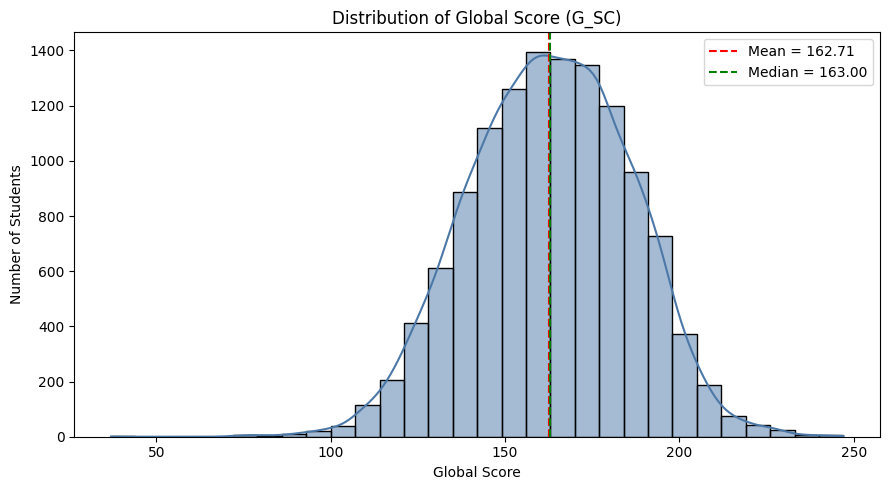

In [ ]:
#2.2 Visualize score distributions
# Figure A1: Histogram and density curve of G_SC
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="G_SC",
    bins=30,
    kde=True,
    color="#4C78A8"
)

plt.axvline(
    df["G_SC"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {df['G_SC'].mean():.2f}"
)

plt.axvline(
    df["G_SC"].median(),
    color="green",
    linestyle="--",
    label=f"Median = {df['G_SC'].median():.2f}"
)

plt.title("Distribution of Global Score (G_SC)")
plt.xlabel("Global Score")
plt.ylabel("Number of Students")
plt.legend()
plt.tight_layout()
plt.show()

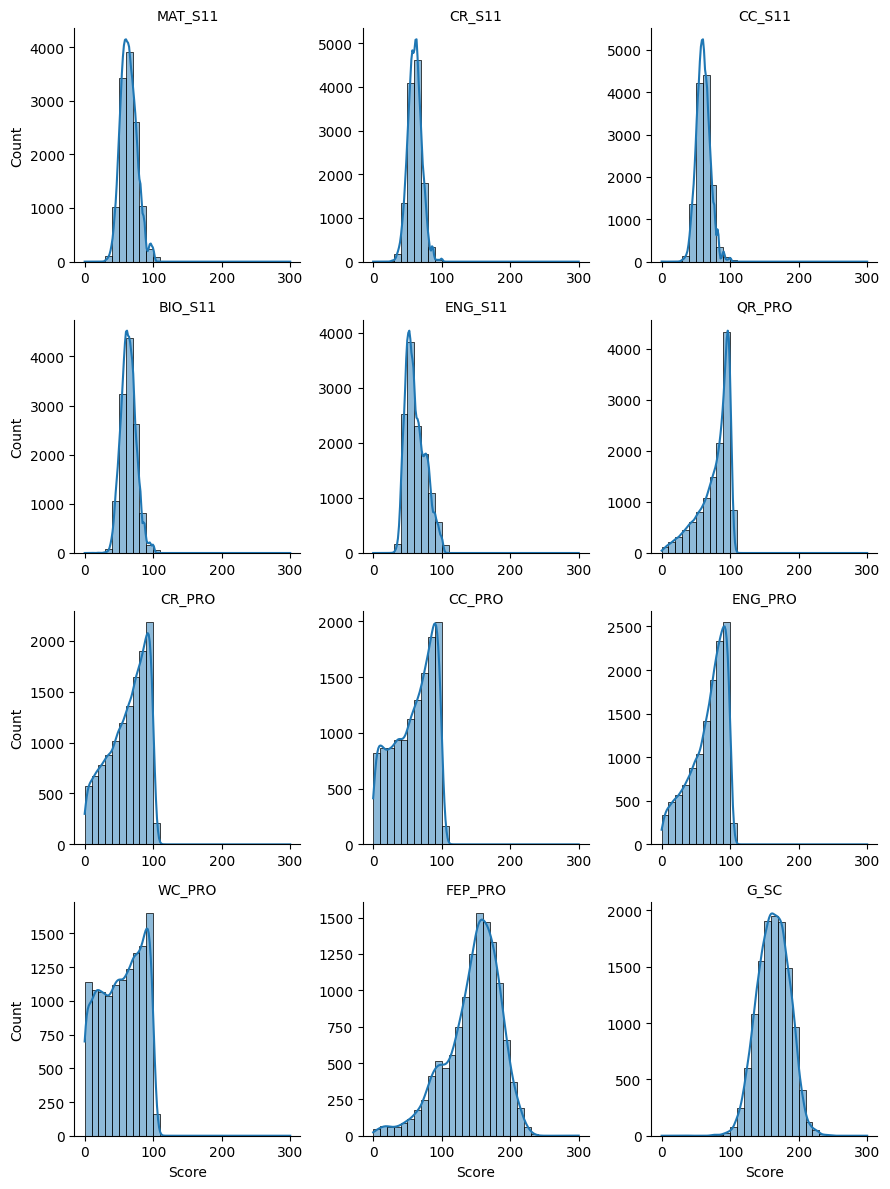

In [ ]:
# The distribution of various achievements
score_long = df[score_cols].melt(
    var_name="Score_Type",
    value_name="Score"
)

g = sns.displot(
    data=score_long,
    x="Score",
    col="Score_Type",
    col_wrap=3,
    bins=30,
    kde=True,
    height=3,
    facet_kws={"sharex": False, "sharey": False}
)

g.set_titles("{col_name}")
g.set_axis_labels("Score", "Count")
plt.show()

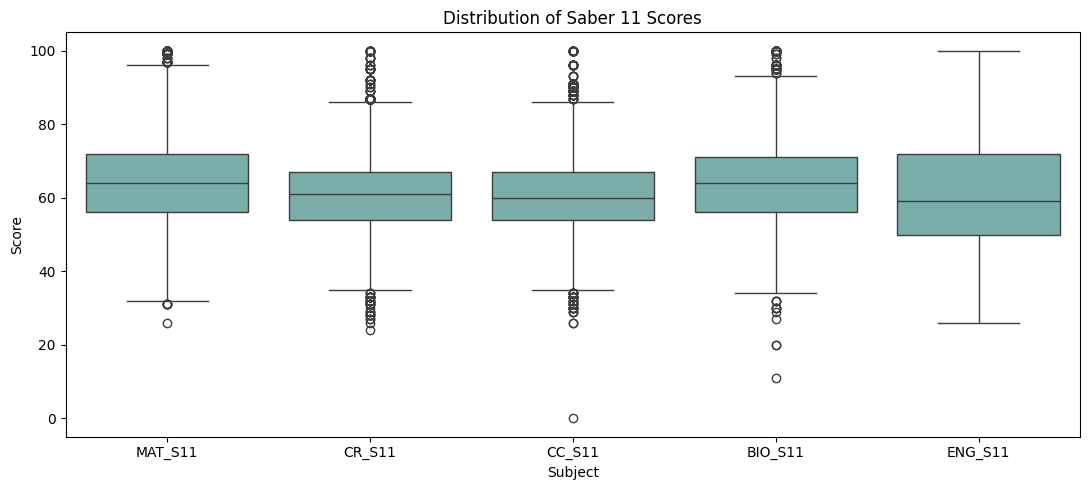

In [ ]:
s11_cols = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11"]

plt.figure(figsize=(11, 5))

sns.boxplot(data=df[s11_cols], color="#72B7B2")

plt.title("Distribution of Saber 11 Scores")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

In [ ]:
#2.3 Outliers and robust statistics

g_sc = df["G_SC"].dropna()

q1 = g_sc.quantile(0.25)
q3 = g_sc.quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = df[
    (df["G_SC"] < lower_fence) |
    (df["G_SC"] > upper_fence)
]

robust_summary = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "Standard deviation",
        "Q1",
        "Q3",
        "IQR",
        "Lower IQR fence",
        "Upper IQR fence",
        "Number of IQR outliers",
        "Percent of IQR outliers",
        "5% trimmed mean",
        "MAD",
        "Skewness"
    ],
    "Value": [
        g_sc.mean(),
        g_sc.median(),
        g_sc.std(),
        q1,
        q3,
        iqr,
        lower_fence,
        upper_fence,
        len(outliers),
        len(outliers) / len(g_sc) * 100,
        trim_mean(g_sc, 0.05),
        median_abs_deviation(g_sc, scale=1),
        skew(g_sc)
    ]
})

display(robust_summary.round(3))

print(f"The number of abnormal values for the IQR of G_SC: {len(outliers)}")
print(f"Proportion of outliers:{len(outliers) / len(g_sc) * 100:.2f}%")

,Statistic,Value
0,Mean,162.710
1,Median,163.000
2,Standard deviation,23.112
3,Q1,147.000
4,Q3,179.000
5,IQR,32.000
6,Lower IQR fence,99.000
7,Upper IQR fence,227.000
8,Number of IQR outliers,67.000
9,Percent of IQR outliers,0.540


The number of abnormal values for the IQR of G_SC: 67
Proportion of outliers:0.54%


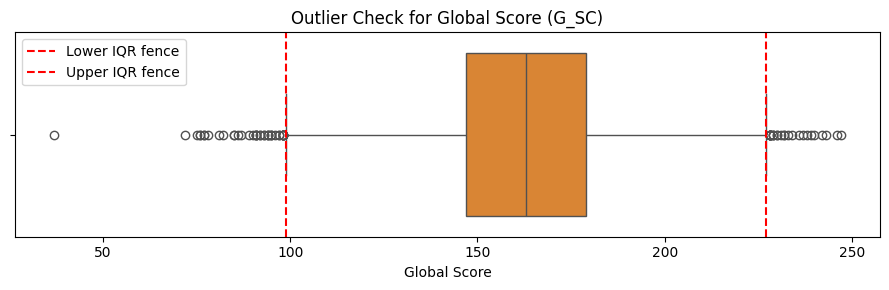

In [ ]:
# Visualization

plt.figure(figsize=(9, 3))

sns.boxplot(x=df["G_SC"], color="#F58518")

plt.axvline(lower_fence, color="red", linestyle="--", label="Lower IQR fence")
plt.axvline(upper_fence, color="red", linestyle="--", label="Upper IQR fence")

plt.title("Outlier Check for Global Score (G_SC)")
plt.xlabel("Global Score")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#2.4 Categorical descriptive statistics
categorical_cols = df.select_dtypes(include="object").columns.tolist()

category_summary = pd.DataFrame({
    "Variable": categorical_cols,
    "Non_missing": [df[col].notna().sum() for col in categorical_cols],
    "Unique_categories": [df[col].nunique(dropna=True) for col in categorical_cols],
    "Most_common_category": [
        df[col].mode().iloc[0] if not df[col].mode().empty else np.nan
        for col in categorical_cols
    ],
    "Most_common_frequency": [
        df[col].value_counts().iloc[0] if not df[col].value_counts().empty else np.nan
        for col in categorical_cols
    ]
})

display(category_summary)

,Variable,Non_missing,Unique_categories,Most_common_category,Most_common_frequency
0,COD_S11,12411,12411,SB11201210000129,1
1,GENDER,12411,2,M,7368
2,EDU_FATHER,12411,12,Complete professional education,3016
3,EDU_MOTHER,12411,12,Complete Secundary,3106
4,OCC_FATHER,12411,12,Independent,2907
5,OCC_MOTHER,12411,12,Home,4658
6,STRATUM,12411,7,Stratum 3,4045
7,SISBEN,12411,6,It is not classified by the SISBEN,7534
8,PEOPLE_HOUSE,12411,13,Four,4767
9,INTERNET,12411,2,Yes,9752


In [ ]:
def category_frequency_table(column):
    result = (
        df[column]
        .value_counts(dropna=False)
        .rename_axis(column)
        .reset_index(name="Count")
    )

    result["Percent"] = result["Count"] / len(df) * 100

    return result


important_categories = [
    "GENDER",
    "STRATUM",
    "EDU_MOTHER",
    "EDU_FATHER",
    "INTERNET",
    "COMPUTER",
    "SCHOOL_NAT",
    "SCHOOL_TYPE"
]

for col in important_categories:
    print(f"\n===== {col} =====")
    display(category_frequency_table(col).round(2))


===== GENDER =====


,GENDER,Count,Percent
0,M,7368,59.37
1,F,5043,40.63



===== STRATUM =====


,STRATUM,Count,Percent
0,Stratum 3,4045,32.59
1,Stratum 2,4029,32.46
2,Stratum 1,1709,13.77
3,Stratum 4,1578,12.71
4,Stratum 5,633,5.10
5,Stratum 6,403,3.25
6,0,14,0.11



===== EDU_MOTHER =====


...

,COMPUTER,Count,Percent
0,Yes,10174,81.98
1,No,2237,18.02



===== SCHOOL_NAT =====


,SCHOOL_NAT,Count,Percent
0,PRIVATE,6565,52.9
1,PUBLIC,5846,47.1



===== SCHOOL_TYPE =====


,SCHOOL_TYPE,Count,Percent
0,ACADEMIC,7834,63.12
1,TECHNICAL/ACADEMIC,3513,28.31
2,TECHNICAL,1059,8.53
3,Not apply,5,0.04


,n,mean,median,std
EDU_MOTHER,,,,
Postgraduate education,997,175.636911,178.0,22.119758
Complete professional education,3059,168.845374,170.0,22.978321
Incomplete Professional Education,502,166.685259,168.0,22.931830
Complete technique or technology,1495,163.242140,163.0,21.943495
Incomplete technical or technological,341,161.879765,164.0,20.744388
Complete Secundary,3106,158.470702,159.0,21.949597
Incomplete Secundary,1056,155.672348,156.0,21.928635
Complete primary,713,155.336606,155.0,22.012293
Incomplete primary,541,154.853974,155.0,21.636024


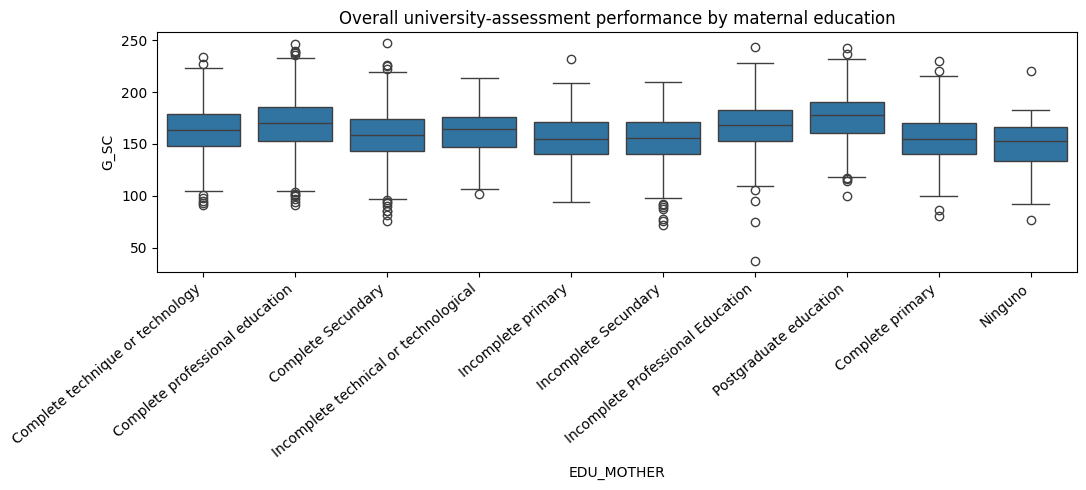

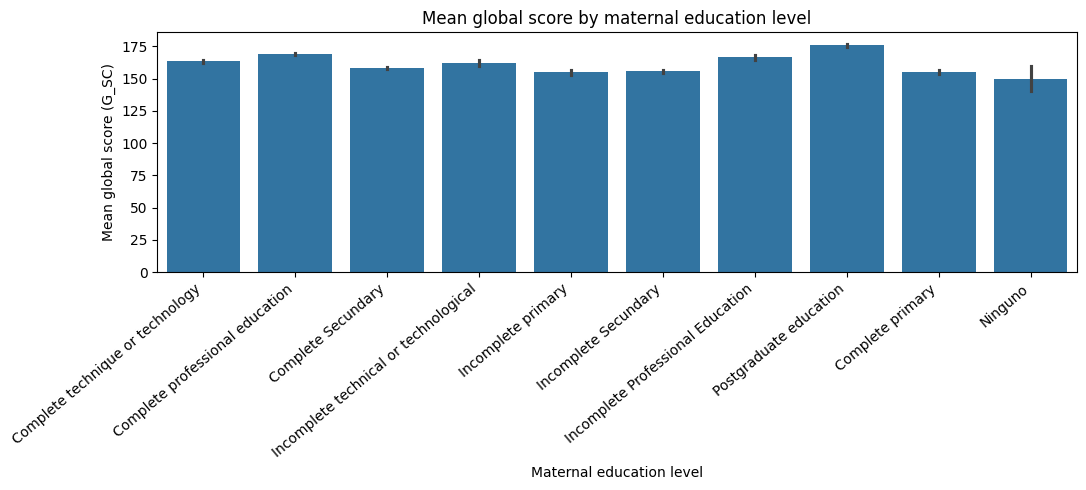

In [ ]:
#3.1.Does parental education influence outcomes, and if so, how much?
mother_clean = df.copy()

mother_clean["EDU_MOTHER"] = (
    mother_clean["EDU_MOTHER"]
    .astype(str)
    .str.strip()
)
mother_clean = mother_clean[
    ~mother_clean["EDU_MOTHER"].isin(["Not sure", "0"])
].copy()
mother_summary = (
    mother_clean.groupby("EDU_MOTHER")["G_SC"]
    .agg(n="count", mean="mean", median="median", std="std")
    .sort_values("mean", ascending=False)
)

display(mother_summary)
#box
plt.figure(figsize=(11, 5))
sns.boxplot(data=mother_clean, x="EDU_MOTHER", y="G_SC")
plt.xticks(rotation=40, ha="right")
plt.title("Overall university-assessment performance by maternal education")
plt.tight_layout()
plt.show()
#bar
plt.figure(figsize=(11, 5))

sns.barplot(
    data=mother_clean,
    x="EDU_MOTHER",
    y="G_SC",
    errorbar=("ci", 95)
)

plt.xticks(rotation=40, ha="right")
plt.title("Mean global score by maternal education level")
plt.xlabel("Maternal education level")
plt.ylabel("Mean global score (G_SC)")
plt.tight_layout()
plt.show()

In [ ]:
#anova: The larger the F value is, the stronger the difference between the groups will be.
groups = [
    group["G_SC"].dropna()
    for _, group in mother_clean.groupby("EDU_MOTHER")
]

f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA: F = {f_stat:.2f}, p = {p_value:.4g}")

#anova:η²（eta- squared）
valid = mother_clean[["EDU_MOTHER", "G_SC"]].dropna()

grand_mean = valid["G_SC"].mean()
ss_between = sum(
    len(g) * (g["G_SC"].mean() - grand_mean) ** 2
    for _, g in valid.groupby("EDU_MOTHER")
)
ss_total = ((valid["G_SC"] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total

print(f"Eta squared = {eta_sq:.3f}")

ANOVA: F = 106.68, p = 5.53e-193
Eta squared = 0.075


,n,mean,median,std
EDU_FATHER,,,,
Postgraduate education,1085,176.985253,179.0,21.734132
Complete professional education,3016,167.765915,169.0,23.030089
Incomplete Professional Education,425,166.917647,168.0,22.685198
Complete technique or technology,1194,164.033501,164.0,22.165359
Incomplete technical or technological,277,162.101083,162.0,21.881198
Not sure,407,160.294840,159.0,22.939555
Complete Secundary,2843,158.785790,159.0,22.114288
Ninguno,123,156.634146,159.0,23.188560
Incomplete Secundary,1091,156.535289,157.0,21.736989


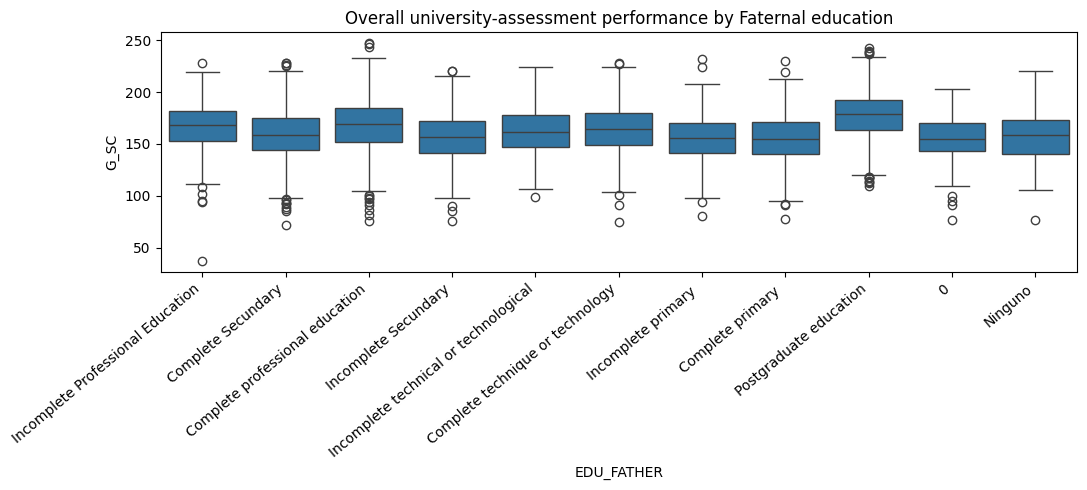

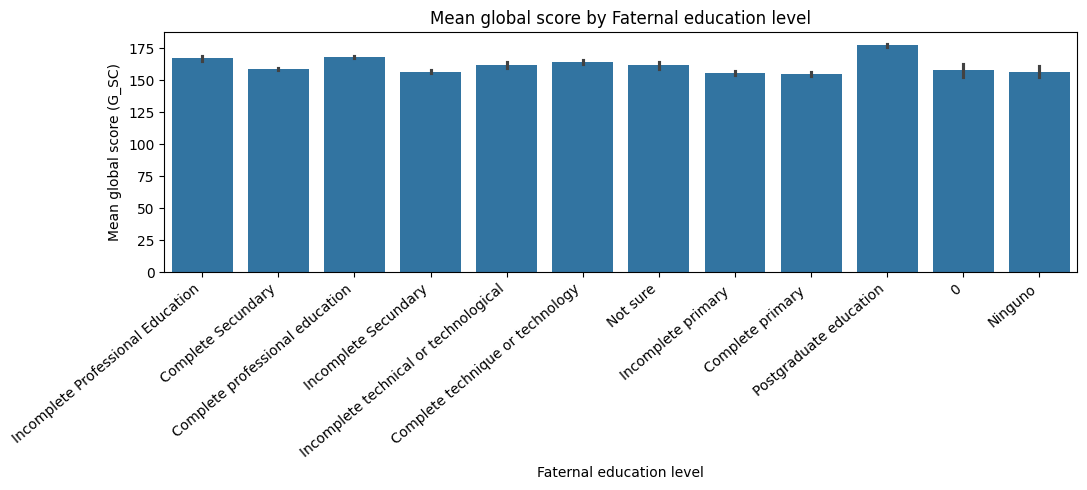

ANOVA: F = 102.04, p = 4.473e-204
Eta squared = 0.078


In [ ]:
#father
father_clean = df[df["EDU_FATHER"] != "Not sure"].copy()
father_clean = father_clean[
    ~father_clean["EDU_FATHER"].isin(["Not sure", "0"])
].copy()
father_summary = (
    df.groupby("EDU_FATHER" )["G_SC"]
      .agg(n="count", mean="mean", median="median", std="std")
      .sort_values("mean", ascending=False)
)
display(father_summary)
#box
plt.figure(figsize=(11, 5))
sns.boxplot(data=father_clean, x="EDU_FATHER", y="G_SC")
plt.xticks(rotation=40, ha="right")
plt.title("Overall university-assessment performance by Faternal education")
plt.tight_layout()
plt.show()
#bar
plt.figure(figsize=(11, 5))

sns.barplot(
    data=mother_clean,
    x="EDU_FATHER",
    y="G_SC",
    errorbar=("ci", 95)
)

plt.xticks(rotation=40, ha="right")
plt.title("Mean global score by Faternal education level")
plt.xlabel("Faternal education level")
plt.ylabel("Mean global score (G_SC)")
plt.tight_layout()
plt.show()
#anova
father_groups = [
    group["G_SC"].dropna()
    for _, group in father_clean.groupby("EDU_FATHER")
]

f_stat, p_value = stats.f_oneway(*father_groups)
print(f"ANOVA: F = {f_stat:.2f}, p = {p_value:.4g}")

#anova: η²（eta- squared）
valid = father_clean[["EDU_FATHER", "G_SC"]].dropna()

grand_mean = valid["G_SC"].mean()
ss_between = sum(
    len(g) * (g["G_SC"].mean() - grand_mean) ** 2
    for _, g in valid.groupby("EDU_FATHER")
)
ss_total = ((valid["G_SC"] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total

print(f"Eta squared = {eta_sq:.3f}")


,n,mean,median,std
STRATUM,,,,
Stratum 6,403,181.511166,184.0,21.879401
Stratum 5,633,177.387046,179.0,21.543236
Stratum 4,1578,172.002535,174.0,21.469094
Stratum 3,4045,163.815328,164.0,21.693970
Stratum 2,4029,158.199305,158.0,22.278029
0,14,154.000000,152.5,21.321712
Stratum 1,1709,152.352838,152.0,21.937401


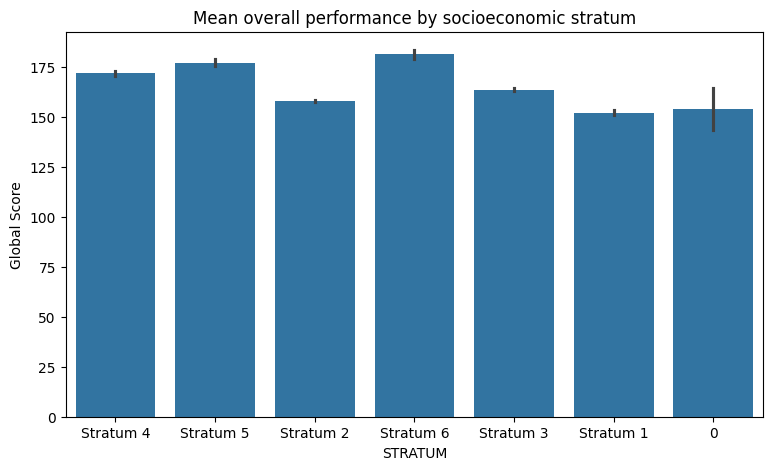

ANOVA: F = 238.77, p = 8.29e-290


In [ ]:
#3.2.Which groups/stratum performs best? Are there differences between groups/stratums? Explain your analysis.
stratum_summary = (
    df.groupby("STRATUM")["G_SC"]
      .agg(n="count", mean="mean", median="median", std="std")
      .sort_values("mean", ascending=False)
)

display(stratum_summary)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x="STRATUM",
    y="G_SC",
    errorbar=("ci", 95)
)
plt.title("Mean overall performance by socioeconomic stratum")
plt.ylabel("Global Score")
plt.show()

stratum_groups = [
    group["G_SC"].dropna()
    for _, group in df.groupby("STRATUM")
]
f_stat, p_value = stats.f_oneway(*stratum_groups)
print(f"ANOVA: F = {f_stat:.2f}, p = {p_value:.4g}")

In [ ]:
#The F-test was significant, indicating that there are differences between the groups.
#Examine which group performed the best.
tmp = df[["STRATUM", "G_SC"]].dropna()

tmp["STRATUM"] = tmp["STRATUM"].astype(str)
tmp["G_SC"] = pd.to_numeric(tmp["G_SC"], errors="coerce")

tukey = pairwise_tukeyhsd(
    endog=tmp["G_SC"],
    groups=tmp["STRATUM"],
    alpha=0.05
)

print(tukey)

    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1    group2  meandiff p-adj   lower    upper  reject
-----------------------------------------------------------
        0 Stratum 1  -1.6472    1.0 -18.9681 15.6738  False
        0 Stratum 2   4.1993 0.9916 -13.0811 21.4797  False
        0 Stratum 3   9.8153 0.6329  -7.4649 27.0956  False
        0 Stratum 4  18.0025 0.0356   0.6758 35.3293   True
        0 Stratum 5   23.387 0.0015   5.9469 40.8272   True
        0 Stratum 6  27.5112 0.0001   9.9637 45.0587   True
Stratum 1 Stratum 2   5.8465    0.0   3.9832  7.7097   True
Stratum 1 Stratum 3  11.4625    0.0   9.6003 13.3247   True
Stratum 1 Stratum 4  19.6497    0.0  17.3963 21.9031   True
Stratum 1 Stratum 5  25.0342    0.0   22.031 28.0374   True
Stratum 1 Stratum 6  29.1583    0.0  25.5841 32.7326   True
Stratum 2 Stratum 3    5.616    0.0   4.1794  7.0527   True
Stratum 2 Stratum 4  13.8032    0.0  11.8864   15.72   True
Stratum 2 Stratum 5  19.1877    0.0  16.

,n,mean,median,std
GENDER,,,,
M,7368,163.690825,164.0,23.582616
F,5043,161.278207,162.0,22.332939


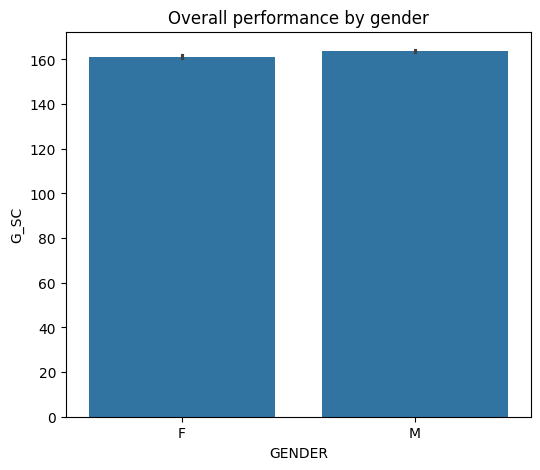

Welch t-test: t = -5.78, p = 7.785e-09
Cohen's d = -0.105


In [ ]:
#3.3.How does each gender perform in the global assessment?
gender_summary = (
    df.groupby("GENDER")["G_SC"]
      .agg(n="count", mean="mean", median="median", std="std")
      .sort_values("mean", ascending=False)
)

display(gender_summary)

plt.figure(figsize=(6, 5))
sns.barplot(
    data=df,
    x="GENDER",
    y="G_SC",
    errorbar=("ci", 95)
)
plt.title("Overall performance by gender")
plt.show()

gender_groups = [
    group["G_SC"].dropna()
    for _, group in df.groupby("GENDER")
]

#Welch t-test for two groups
female_scores = df.loc[df["GENDER"] == "F", "G_SC"].dropna()
male_scores = df.loc[df["GENDER"] == "M", "G_SC"].dropna()

t_stat, p_value = stats.ttest_ind(
    female_scores,
    male_scores,
    equal_var=False
)

print(f"Welch t-test: t = {t_stat:.2f}, p = {p_value:.4g}")

#cohen's d
#|d| ≈ 0.20：Minor effect; |d| ≈ 0.50：Medium effect; |d| ≈ 0.80: Strong effect。
g1, g2 = gender_groups

pooled_sd = np.sqrt(
    ((len(g1) - 1) * g1.var(ddof=1) + (len(g2) - 1) * g2.var(ddof=1))
    / (len(g1) + len(g2) - 2)
)

cohens_d = (g1.mean() - g2.mean()) / pooled_sd
print(f"Cohen's d = {cohens_d:.3f}")

#Summary:
#Multiple groups:
#1. Group mean table: Answer "Which stratum performed the best";
#2. ANOVA F-test: Answer "Is there at least an inter-group difference overall?" p < 0.05 is significant
#In the ANOVA test, η² (eta-squared): η² ≈ 0.01: small effect; η² ≈ 0.06: medium effect; η² ≈ 0.14: large effect
#F / p value answers "Does the difference exist?"; η² answers "How large is the difference"
#3. When F is significant, Tukey HSD: Answer "Which two strata have a significant difference specifically"
#Two groups:
#1. Group mean table: Answer "Which gender performed better";
#2. t-test (to check the inter-group difference) p < 0.05 is significant
#3. Calculate Cohen's absolute d value: |d| ≈ 0.20: small effect; |d| ≈ 0.50: medium effect; |d| ≈ 0.80: large effect
#Explanation of the meaning of effect size Cohen's d: Avoid interpreting very small score differences too importantly due to a large sample size.


,n
ACADEMIC_PROGRAM,
INDUSTRIAL ENGINEERING,5318
CIVIL ENGINEERING,3320
MECHANICAL ENGINEERING,1135
CHEMICAL ENGINEERING,1000
ELECTRONIC ENGINEERING,849
ELECTRIC ENGINEERING,278
MECHATRONICS ENGINEERING,82
CATASTRAL ENGINEERING AND GEODESY,78
PRODUCTION ENGINEERING,60


numbers of students： 12287
numbers of programs： 13


,n,mean,median,std
ACADEMIC_PROGRAM,,,,
CHEMICAL ENGINEERING,1000,176.70,177.0,18.69
CATASTRAL ENGINEERING AND GEODESY,78,174.60,176.0,14.95
ELECTRIC ENGINEERING,278,173.99,174.5,19.35
PRODUCTION ENGINEERING,60,172.90,176.5,20.56
TOPOGRAPHIC ENGINEERY,42,172.71,174.0,15.76
ELECTRONIC ENGINEERING,849,166.87,167.0,22.20
MECHANICAL ENGINEERING,1135,166.05,166.0,23.26
CIVIL ENGINEERING,3320,161.11,161.0,22.83
ELECTRIC ENGINEERING AND TELECOMMUNICATIONS,47,160.43,160.0,22.15


One-way ANOVA: F(12, 12274) = 62.42, p = 6.076e-148
Eta-squared (η²) = 0.058


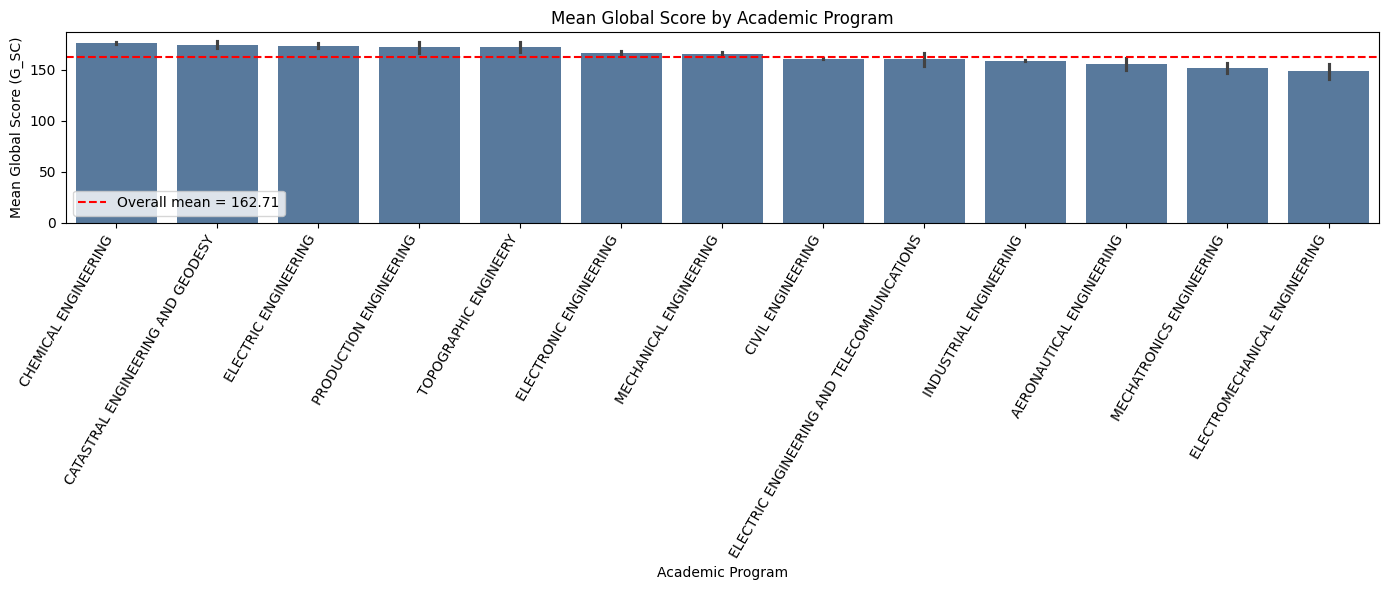

In [ ]:
#3.4.Use your analysis to understand the results.  What did you find interesting, and can you make any recommendations or inferences?
program_counts = df["ACADEMIC_PROGRAM"].value_counts()
display(program_counts.to_frame(name="n"))

#A professional with a sample size of no less than 30 people retained
valid_programs = program_counts[program_counts >= 30].index

program_df = df[
    df["ACADEMIC_PROGRAM"].isin(valid_programs)
].copy()

print("numbers of students：", len(program_df))
print("numbers of programs：", program_df["ACADEMIC_PROGRAM"].nunique())

#Descriptive statistics table for each engineering discipline
program_summary = (
    program_df.groupby("ACADEMIC_PROGRAM")["G_SC"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        std="std"
    )
    .sort_values("mean", ascending=False)
)

display(program_summary.round(2))

# ANOVA: F test
program_groups = [
    group["G_SC"].dropna()
    for _, group in program_df.groupby("ACADEMIC_PROGRAM")
]

f_stat, p_value = stats.f_oneway(*program_groups)

df_between = len(program_groups) - 1
df_within = len(program_df) - len(program_groups)

print(
    f"One-way ANOVA: "
    f"F({df_between}, {df_within}) = {f_stat:.2f}, "
    f"p = {p_value:.4g}"
)

#eta-squared（η²）

grand_mean = program_df["G_SC"].mean()

ss_between = sum(
    len(group) * (group["G_SC"].mean() - grand_mean) ** 2
    for _, group in program_df.groupby("ACADEMIC_PROGRAM")
)

ss_total = (
    (program_df["G_SC"] - grand_mean) ** 2
).sum()

eta_sq_program = ss_between / ss_total

print(f"Eta-squared (η²) = {eta_sq_program:.3f}")

# mean bar
program_order = program_summary.index.tolist()

plt.figure(figsize=(14, 6))

sns.barplot(
    data=program_df,
    x="ACADEMIC_PROGRAM",
    y="G_SC",
    order=program_order,
    errorbar=("ci", 95),
    color="#4C78A8"
)

plt.axhline(
    df["G_SC"].mean(),
    color="red",
    linestyle="--",
    label=f"Overall mean = {df['G_SC'].mean():.2f}"
)

plt.title("Mean Global Score by Academic Program")
plt.xlabel("Academic Program")
plt.ylabel("Mean Global Score (G_SC)")
plt.xticks(rotation=60, ha="right")
plt.legend()
plt.tight_layout()
plt.show()